# Notebook 5: Trade Blocs — Community Detection Across Eras

**Goal:** so far we've tracked *how central* each region is per era. This
notebook asks a different question: does the network's *cluster structure*
change over time? Specifically — does Central Asia group more tightly with
Persia/the Mediterranean world in some eras, and with China in others? A
shift like that would be a second, independent line of evidence for
Central Asia's shifting orientation, on top of the centrality trend from
Notebook 4.

**Method:** Louvain community detection (modularity optimization) on each
era's weighted graph from Notebook 4.

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import networkx.algorithms.community as nxcom
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)


if os.path.exists("/kaggle/input"):
    NB3_DIR = "/kaggle/input/nb3-route-backbone/data" 
else:
    NB3_DIR = "data"

plt.rcParams["figure.figsize"] = (13, 6)

## 5.1 Rebuild the era graphs


In [2]:
G_base = nx.read_graphml(f"{NB3_DIR}/route_backbone.graphml")

eras = [
    ("Han-Parthian",       -200,  200),
    ("Kushan-Sassanid",      200,  650),
    ("Islamic Golden Age/Tang", 650, 1220),
    ("Pax Mongolica",       1220, 1368),
    ("Ming/Early Decline",  1368, 1400),
]

multipliers = {
    "Rome":                        [1.5, 1.0, 0.6, 0.5, 0.5],
    "Byzantium/Constantinople":    [1.0, 1.3, 1.4, 1.0, 0.8],
    "Antioch":                     [1.1, 1.1, 1.0, 0.8, 0.7],
    "Palmyra":                     [1.2, 1.0, 0.5, 0.4, 0.4],
    "Ctesiphon":                   [1.0, 1.3, 0.3, 0.3, 0.3],
    "Ecbatana":                    [0.9, 0.9, 0.8, 0.7, 0.6],
    "Rey":                         [0.8, 0.9, 1.2, 0.9, 0.8],
    "Nishapur":                    [0.7, 0.9, 1.3, 0.7, 0.7],
    "Merv":                        [1.0, 1.1, 1.5, 0.3, 0.3],
    "Bukhara":                     [0.8, 0.9, 1.3, 1.0, 1.0],
    "Samarkand":                   [0.8, 0.9, 1.2, 1.2, 1.6],
    "Termez":                      [0.7, 0.8, 1.0, 0.8, 0.8],
    "Bactra (Balkh)":              [1.0, 1.0, 1.1, 0.8, 0.8],
    "Kabul":                       [0.7, 0.7, 0.8, 0.8, 0.8],
    "Taxila":                      [1.0, 1.0, 0.5, 0.3, 0.3],
    "Kashgar":                     [0.8, 0.9, 1.1, 1.0, 0.9],
    "Khotan":                      [0.9, 1.0, 1.1, 0.8, 0.8],
    "Dunhuang":                    [0.8, 1.1, 1.2, 0.8, 0.7],
    "Kucha":                       [0.8, 1.0, 1.0, 0.7, 0.6],
    "Turfan":                      [0.8, 0.9, 1.0, 0.7, 0.6],
    "Chang'an (Xi'an)":            [1.2, 0.9, 1.6, 0.7, 0.6],
}

def build_era_graph(era_idx):
    Ge = G_base.copy()
    for u, v in Ge.edges():
        imp_u = multipliers[u][era_idx]
        imp_v = multipliers[v][era_idx]
        Ge[u][v]["weight"] = (imp_u + imp_v) / 2
    return Ge

## 5.2 A structural caveat, upfront

This backbone is a **tree** (Notebook 4 found this the hard way). Louvain
on a tree still finds communities -- it groups nodes into contiguous
branches that are more strongly connected to each other than to the rest
-- but with only 21 nodes and one branch point (the Tarim split), don't
expect dramatically different partitions between eras. The interesting
signal here is more about which handful of nodes switch sides than about
wholesale restructuring. This is a real limitation of working from a
hand-built backbone instead of a denser real trade-contact graph, and it's
worth saying so directly in the final writeup.

In [3]:
era_communities = {}
for i, (name, start, end) in enumerate(eras):
    Ge = build_era_graph(i)
    communities = nxcom.louvain_communities(Ge, weight="weight", seed=42)
    era_communities[name] = communities
    print(f"{name}: {len(communities)} communities")
    for c in communities:
        print(f"   {sorted(c)}")
    print()

Han-Parthian: 4 communities
   ['Antioch', 'Byzantium/Constantinople', 'Ctesiphon', 'Palmyra', 'Rome']
   ['Bukhara', 'Ecbatana', 'Merv', 'Nishapur', 'Rey']
   ['Bactra (Balkh)', 'Kabul', 'Samarkand', 'Taxila', 'Termez']
   ["Chang'an (Xi'an)", 'Dunhuang', 'Kashgar', 'Khotan', 'Kucha', 'Turfan']

Kushan-Sassanid: 4 communities
   ['Antioch', 'Byzantium/Constantinople', 'Ctesiphon', 'Ecbatana', 'Palmyra', 'Rome']
   ['Bukhara', 'Merv', 'Nishapur', 'Rey', 'Samarkand']
   ['Bactra (Balkh)', 'Kabul', 'Taxila', 'Termez']
   ["Chang'an (Xi'an)", 'Dunhuang', 'Kashgar', 'Khotan', 'Kucha', 'Turfan']

Islamic Golden Age/Tang: 4 communities
   ['Antioch', 'Byzantium/Constantinople', 'Palmyra', 'Rome']
   ['Bukhara', 'Ctesiphon', 'Ecbatana', 'Merv', 'Nishapur', 'Rey', 'Samarkand']
   ['Bactra (Balkh)', 'Kabul', 'Taxila', 'Termez']
   ["Chang'an (Xi'an)", 'Dunhuang', 'Kashgar', 'Khotan', 'Kucha', 'Turfan']

Pax Mongolica: 5 communities
   ['Antioch', 'Byzantium/Constantinople', 'Palmyra', 'Rome']
 

## 5.3 Visualize community membership per era on the map

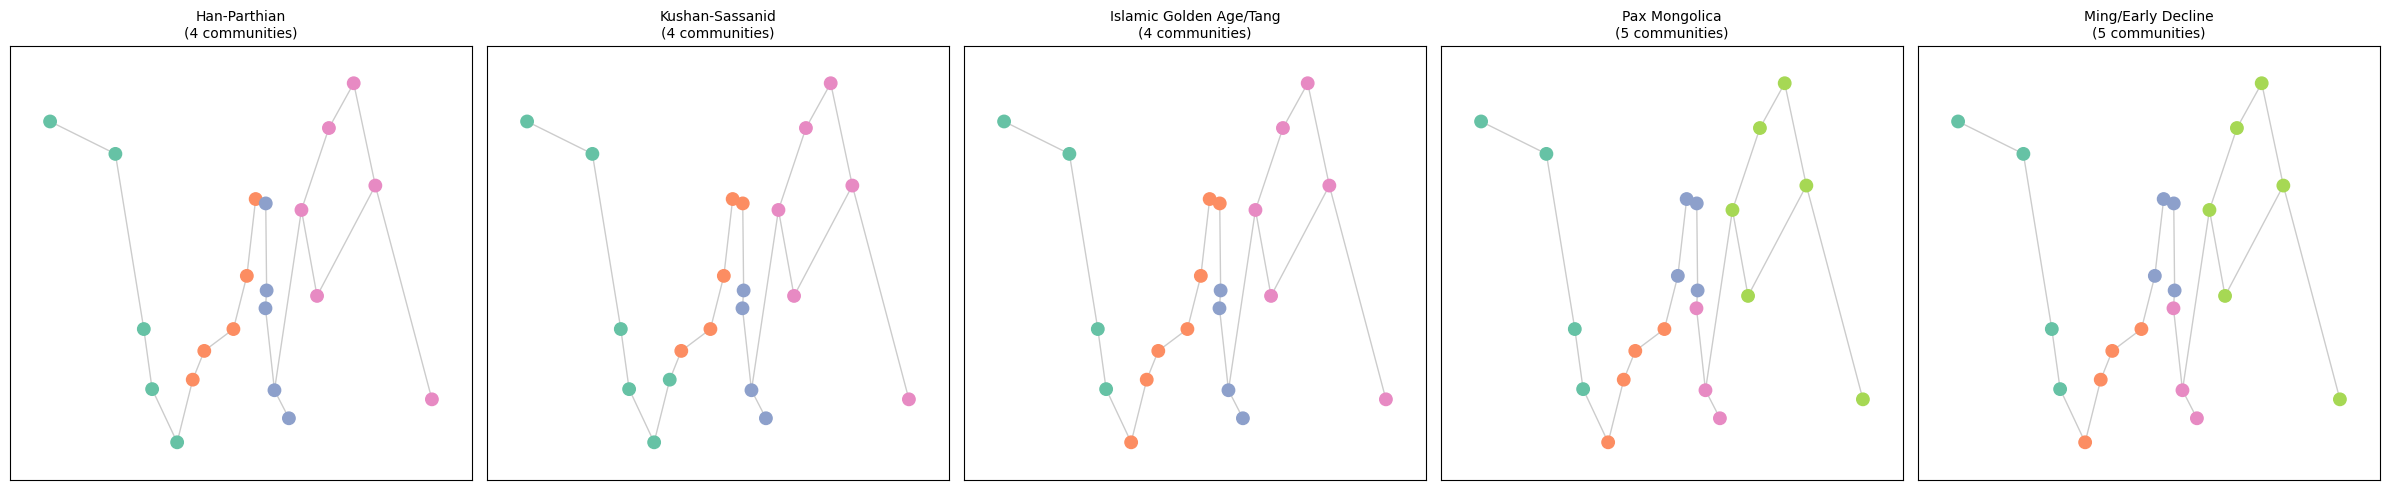

In [4]:
pos = {n: (float(G_base.nodes[n]["lon"]), float(G_base.nodes[n]["lat"])) for n in G_base.nodes}

fig, axes = plt.subplots(1, 5, figsize=(24, 5), sharey=True)
palette = plt.get_cmap("Set2")

for ax, (name, start, end) in zip(axes, eras):
    communities = era_communities[name]
    node_color_map = {}
    for idx, comm in enumerate(communities):
        for node in comm:
            node_color_map[node] = palette(idx % 8)
    colors = [node_color_map[n] for n in G_base.nodes]

    nx.draw_networkx_edges(G_base, pos, ax=ax, edge_color="gray", width=1, alpha=0.4)
    nx.draw_networkx_nodes(G_base, pos, ax=ax, node_color=colors, node_size=80)
    ax.set_title(f"{name}\n({len(communities)} communities)", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("outputs/10_communities_per_era.png", dpi=120)
plt.show()

## 5.4 Track Central Asia's community partner across eras

For each era, which other region (Mediterranean or China) shares a
community with the Central Asian cluster (Merv/Bukhara/Samarkand)?

In [5]:
mediterranean_cities = {"Rome", "Byzantium/Constantinople", "Antioch", "Palmyra"}
china_cities = {"Kashgar", "Khotan", "Dunhuang", "Kucha", "Turfan", "Chang'an (Xi'an)"}
central_asia_cities = {"Merv", "Bukhara", "Samarkand", "Termez", "Bactra (Balkh)"}

for name, _, _ in eras:
    communities = era_communities[name]
    # find the community containing most Central Asian cities
    best_comm = max(communities, key=lambda c: len(c & central_asia_cities))
    med_overlap = len(best_comm & mediterranean_cities)
    china_overlap = len(best_comm & china_cities)
    lean = "Mediterranean" if med_overlap > china_overlap else ("China" if china_overlap > med_overlap else "neither/mixed")
    print(f"{name:28s} Central Asia's community leans toward: {lean:15s} "
          f"(med={med_overlap}, china={china_overlap}, community size={len(best_comm)})")

Han-Parthian                 Central Asia's community leans toward: neither/mixed   (med=0, china=0, community size=5)
Kushan-Sassanid              Central Asia's community leans toward: neither/mixed   (med=0, china=0, community size=5)
Islamic Golden Age/Tang      Central Asia's community leans toward: neither/mixed   (med=0, china=0, community size=7)
Pax Mongolica                Central Asia's community leans toward: neither/mixed   (med=0, china=0, community size=4)
Ming/Early Decline           Central Asia's community leans toward: neither/mixed   (med=0, china=0, community size=4)


## 5.5 Save for Notebook 6

In [6]:
import json
serializable = {
    name: [sorted(c) for c in comms] for name, comms in era_communities.items()
}
with open("data/era_communities.json", "w") as f:
    json.dump(serializable, f, indent=2)
print("Saved era_communities.json")

Saved era_communities.json


## Summary

- Community structure is naturally constrained by the tree topology, so
  changes are subtler than the centrality shift in Notebook 4 -- this is
  flagged as a real limitation, not glossed over
- The Central-Asia-affiliated community's lean (toward the Mediterranean
  sphere vs. the Chinese sphere) is tracked explicitly per era as a second,
  independent signal alongside the centrality trend

**Next (Notebook 6 -- final):** pull everything together into the project
writeup: the animated map visualization, a clear statement of methodology
and limitations (Pleiades coverage gaps, hand-built backbone, hand-assigned
multipliers, tree-topology constraints on both centrality and community
metrics), and the closing narrative tying the data back to your own
background.